# R1: Do calibration weights need to vary with latitude, region or climate regime?

SeasonBlend research notebook, ECMWF AI Weather Quest. It runs top to bottom in JupyterLab from
`notebooks/`, using the research venv (`.venv-research`). All numbers below come from the
real data cached by the pipeline:

- the ECMWF IFS ENS runs of 2026 from dynamical.org;
- the official ERA5 weekly observations and 20-year quintile boundaries from ECBox;
- the BoM and NOAA CPC climate indices.

No synthetic data is used.

**Inputs.**

- `data/research/rows_<var>_p<w>.npz` (from `python -m aiwq.research`): RPS sufficient statistics
  for every latitude row, every setting combination and every verified week. Also the per-week
  fields of SeasonBlend's selected setting.
- `data/research/qm_<var>_p<w>.npz` (from `python -m aiwq.research_qm`): the quantile-mapping
  reference experiment.
- `data/params_control.json`: SeasonBlend refitted under the experiment harness (R0).

**Outputs.** All outputs go to `results/experiments/R1/`: tables (CSV/JSON), figures (PNG and PDF),
fold definitions and the decision record.

In [1]:
import sys, json, subprocess, platform, datetime as dt
from pathlib import Path
import os
ROOT = Path(os.environ.get("AIWQ_ROOT", Path.cwd()))
while not (ROOT / "config.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent  # run from notebooks/ or the repository root
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from aiwq import r1, calib
from aiwq.grid import LAT, LON, area_weights
from aiwq.config import load_config, VARIABLES, WINDOWS

cfg = load_config(ROOT / "config.toml", experiment="control")
RD = cfg.data_dir / "research"
OUT = ROOT / "results" / "experiments" / "R1"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
PAIRS = [(v, w) for v in VARIABLES for w in WINDOWS]
NAMES = {"tas": "2 m temperature", "mslp": "Mean sea level pressure", "pr": "Precipitation"}
WIN = {1: "days 19-25", 2: "days 26-32"}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
                     "figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

rows = {p: np.load(RD / f"rows_{p[0]}_p{p[1]}.npz") for p in PAIRS}
control = json.loads(cfg.params_path.read_text())
commit = subprocess.run(["git", "-C", str(ROOT), "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print("commit", commit, "| python", platform.python_version(), "| numpy", np.__version__)

commit 59125fe | python 3.14.2 | numpy 2.5.4


## 1. Provenance and data inventory

In [2]:
from aiwq.ens import cached_inits
from aiwq.obs import available_weeks
idx = pd.read_csv(cfg.indices_dir / "state_at_init.csv", parse_dates=["init"])
inv = {
    "generated_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "git_commit": commit,
    "ens_runs_cached": [str(d) for d in cached_inits(cfg)],
    "era5_weeks": {v: [str(available_weeks(cfg, v)[0]), str(available_weeks(cfg, v)[-1]), len(available_weeks(cfg, v))] for v in VARIABLES},
    "verified_runs": {f"{v}_p{w}": int(rows[(v, w)]["terms"].shape[3]) for v, w in PAIRS},
    "first_last_verified_init": {f"{v}_p{w}": [str(rows[(v, w)]["inits"][0]), str(rows[(v, w)]["inits"][-1])] for v, w in PAIRS},
    "setting_grid": {"lambda": cfg.lambdas, "spread": cfg.spreads, "prob_smoothing": cfg.prob_smooth_sigmas},
    "exclude_days": cfg.exclude_days,
    "indices": {"rmm": "BoM IDCKGEM000 rmm.74toRealtime.txt (lag 2 d)", "nino34": "NOAA CPC wksst9120.for (lag 8 d)",
                "iod": "BoM IDCK000072 iod_1.txt (lag 4 d)"},
    "software": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": matplotlib.__version__},
}
(OUT / "provenance.json").write_text(json.dumps(inv, indent=1))
print(json.dumps({k: v for k, v in inv.items() if k not in ("ens_runs_cached",)}, indent=1))

{
 "generated_utc": "2026-11-18T19:41:10+00:00",
 "git_commit": "59125fe",
 "era5_weeks": {
  "tas": [
   "2024-01-15",
   "2026-11-02",
   147
  ],
  "mslp": [
   "2024-01-15",
   "2026-11-02",
   147
  ],
  "pr": [
   "2024-01-15",
   "2026-11-02",
   147
  ]
 },
 "verified_runs": {
  "tas_p1": 42,
  "tas_p2": 41,
  "mslp_p1": 42,
  "mslp_p2": 41,
  "pr_p1": 42,
  "pr_p2": 41
 },
 "first_last_verified_init": {
  "tas_p1": [
   "2026-01-01",
   "2026-10-15"
  ],
  "tas_p2": [
   "2026-01-01",
   "2026-10-08"
  ],
  "mslp_p1": [
   "2026-01-01",
   "2026-10-15"
  ],
  "mslp_p2": [
   "2026-01-01",
   "2026-10-08"
  ],
  "pr_p1": [
   "2026-01-01",
   "2026-10-15"
  ],
  "pr_p2": [
   "2026-01-01",
   "2026-10-08"
  ]
 },
 "setting_grid": {
  "lambda": [
   0.0,
   0.5,
   0.75,
   1.0
  ],
  "spread": [
   1.0,
   1.25,
   1.5,
   1.75,
   2.0
  ],
  "prob_smoothing": [
   0.0,
   1.0,
   2.0
  ]
 },
 "exclude_days": 21,
 "indices": {
  "rmm": "BoM IDCKGEM000 rmm.74toRealtime.txt (lag 

## 2. Audit of R0: does the experiment framework reproduce SeasonBlend exactly? (R1-A)

The row-level statistics are summed into SeasonBlend's three latitude bands. The weights,
in-sample score and fully cross-validated weekly scores must equal `data/params_control.json`.

In [3]:
bands = r1.Scheme("SeasonBlend (3 bands)", r1.band_basis())
def ctrl_combo(z):
    L, S, P = z["terms"].shape[:3]
    return int(np.ravel_multi_index(tuple(z["control_combo"]), (L, S, P)))
audit = []
cv = {}
for v, w in PAIRS:
    z = rows[(v, w)]
    al, ga, a, c, ins = r1.in_sample(z["terms"], bands, ctrl_combo(z))
    res = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), bands)
    cv[("A", v, w)] = res
    p = control[v][str(w)]
    audit.append({"variable": v, "window": w, "N": len(res.rps),
                  "in-sample (control)": p["scores"]["final"], "in-sample (rows)": ins,
                  "CV (control)": p["scores"]["final_cv"], "CV (rows)": res.rpss_ratio,
                  "max |weekly RPS diff|": float(np.max(np.abs(res.rps - np.array(p["weekly"]["rps_final_cv"])))),
                  "max |weight diff|": float(max(np.max(np.abs(al - p["a"])), np.max(np.abs(ga - p["c"])))),
                  "CV, leaderboard convention": res.rpss_leaderboard})
audit = pd.DataFrame(audit)
audit.to_csv(OUT / "R1A_reproduction.csv", index=False)
audit.round(6)

,variable,window,N,in-sample (control),in-sample (rows),CV (control),CV (rows),max |weekly RPS diff|,max |weight diff|,"CV, leaderboard convention"
0,tas,1,42,0.114805,0.114805,0.110712,0.110712,0.0,0.0,0.107932
1,tas,2,41,0.095914,0.095914,0.090667,0.090667,0.0,0.0,0.088080
2,mslp,1,42,0.196224,0.196224,0.186408,0.186408,0.0,0.0,0.180923
3,mslp,2,41,0.154419,0.154419,0.144830,0.144830,0.0,0.0,0.140295
4,pr,1,42,0.083373,0.083373,0.081776,0.081776,0.0,0.0,0.081466
5,pr,2,41,0.072518,0.072518,0.070816,0.070816,0.0,0.0,0.070663


**Two scoring conventions.** The fit chooses settings by $1-\sum_i \mathrm{RPS}_i/\sum_i \mathrm{RPS}^{clim}_i$
("ratio"). The competition's period-aggregated leaderboard, as stated on the Evaluation System page
(read 18 November 2026), is the *mean of weekly RPSS*, $\frac1N\sum_i(1-\mathrm{RPS}_i/\mathrm{RPS}^{clim}_i)$
("leaderboard"). Both are reported below. The leaderboard convention gives every week equal weight,
whatever its climatological RPS.

## 3. What can 42 runs identify? Climate-regime sample sizes

The index values below were known at each initialisation (publication lags in
`aiwq/indices.py`). They are shown for the verified runs of days 19-25.

C:\Users\Stephen Nyaranga\AppData\Local\Temp\ipykernel_46648\2738551515.py:7: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy = tr["init"].dt.dayofyear.to_numpy() * 2 * np.pi / 365.25


mjo_active  MJO active (amp>=1)  MJO inactive
enso                                         
El Nino                      20             6
La Nina                       2             3
neutral                       7             4 

Correlation of Nino 3.4 with time across the 42 verified runs: +0.992
Share of Nino 3.4 variance explained by a seasonal cycle (sin, cos of day of year): 0.91
MJO amplitude: active at 29 of 42 runs; lag-1 autocorrelation of amplitude +0.24


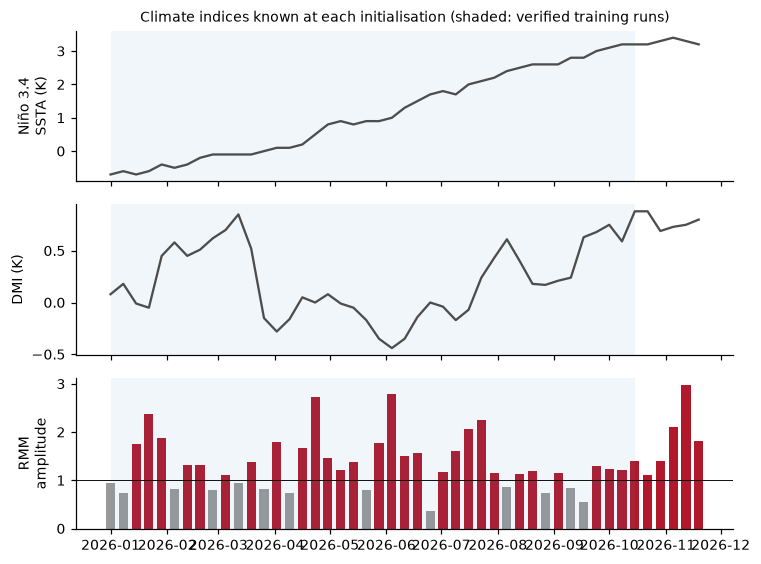

In [4]:
z = rows[("tas", 1)]
tr = pd.DataFrame({"init": pd.to_datetime(z["inits"])}).merge(idx, on="init", how="left")
tr["t"] = (tr["init"] - tr["init"].min()).dt.days
counts = pd.crosstab(tr["enso"], tr["mjo_active"].map({1: "MJO active (amp>=1)", 0: "MJO inactive"}))
r_time = np.corrcoef(tr["t"], tr["nino34"])[0, 1]
# season: a seasonal-cycle regression of Nino 3.4 on sin/cos of day of year
doy = tr["init"].dt.dayofyear.to_numpy() * 2 * np.pi / 365.25
Xs = np.c_[np.ones(len(tr)), np.sin(doy), np.cos(doy)]
fit = np.linalg.lstsq(Xs, tr["nino34"].to_numpy(), rcond=None)[0]
r2_season = 1 - np.var(tr["nino34"] - Xs @ fit) / np.var(tr["nino34"])
print(counts, "\n")
print(f"Correlation of Nino 3.4 with time across the {len(tr)} verified runs: {r_time:+.3f}")
print(f"Share of Nino 3.4 variance explained by a seasonal cycle (sin, cos of day of year): {r2_season:.2f}")
print(f"MJO amplitude: active at {int(tr['mjo_active'].sum())} of {len(tr)} runs; lag-1 autocorrelation of amplitude "
      f"{np.corrcoef(tr['mjo_amp'][:-1], tr['mjo_amp'][1:])[0, 1]:+.2f}")
fig, ax = plt.subplots(3, 1, figsize=(7, 5.2), sharex=True)
ax[0].plot(idx["init"], idx["nino34"], "-", color="0.3"); ax[0].set_ylabel("Niño 3.4\nSSTA (K)")
ax[1].plot(idx["init"], idx["iod"], "-", color="0.3"); ax[1].set_ylabel("DMI (K)")
ax[2].bar(idx["init"], idx["mjo_amp"], width=5, color=np.where(idx["mjo_amp"] >= 1, "#b2182b", "0.6"))
ax[2].axhline(1, color="k", lw=0.6); ax[2].set_ylabel("RMM\namplitude")
for a in ax:
    a.axvspan(tr["init"].min(), tr["init"].max(), color="#4393c3", alpha=0.08, lw=0)
ax[0].set_title("Climate indices known at each initialisation (shaded: verified training runs)")
fig.tight_layout(); savefig(fig, "fig1_regime_indices")

## 4. R1-B: continuous latitude-dependent weights

**Hypothesis.** The three latitude bands give SeasonBlend's blend weights jumps at 30°N and 30°S
(visible as seams in the maps). Weights that vary smoothly with latitude would remove the jumps
and improve skill near the band edges.

**Pre-specified primary scheme (G7).** Gaussian kernels centred every 30° (90°N ... 90°S), 15°
wide, normalised to a partition of unity. The weights are therefore convex combinations of the
7 node values: 14 blend parameters, against 6 for the bands.

**Sensitivity checks** (stated before scoring): 6 bands of 30°; 13 nodes every 15° with 7.5°
width.

**Validation.** Each held-out week is predicted with settings and weights fitted without it
and without the weeks within 21 days of it. This is identical to SeasonBlend's fully
cross-validated score (section 2).

In [5]:
import time
schemes = {
    "A": bands,
    "B": r1.Scheme("R1-B smooth, 7 nodes (primary)", r1.gaussian_basis()),
    "B6": r1.Scheme("6 bands of 30°", r1.band_basis(((90, 60), (60, 30), (30, 0), (0, -30), (-30, -60), (-60, -90)))),
    "B13": r1.Scheme("smooth, 13 nodes", r1.gaussian_basis(tuple(range(90, -91, -15)), 7.5)),
}
t0 = time.time()
for key in ("B", "B6", "B13"):
    for v, w in PAIRS:
        z = rows[(v, w)]
        cv[(key, v, w)] = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), schemes[key])
print(f"cross-validation of 3 schemes x 6 pairs: {time.time() - t0:.0f} s")

def raw_rps(z):
    L, S, P = z["terms"].shape[:3]
    k = np.ravel_multi_index((list(z["lambdas"]).index(0.0), list(z["spreads"]).index(1.0), list(z["sigmas"]).index(0.0)), (L, S, P))
    T = z["terms"].reshape(L * S * P, *z["terms"].shape[3:])[k]
    return np.array([T[i, :, 0].sum() - 2 * T[i, :, 3].sum() + T[i, :, 5].sum() for i in range(T.shape[0])])

table = []
for v, w in PAIRS:
    z = rows[(v, w)]
    clim = cv[("A", v, w)].clim
    rr = raw_rps(z)
    row = {"variable": v, "window": w, "N": len(clim),
           "raw ECMWF": 1 - rr.sum() / clim.sum(), "raw ECMWF (lb)": np.mean(1 - rr / clim)}
    for key in schemes:
        row[key] = cv[(key, v, w)].rpss_ratio
        row[key + " (lb)"] = cv[(key, v, w)].rpss_leaderboard
    table.append(row)
scores = pd.DataFrame(table)
mean = scores.drop(columns=["variable", "window", "N"]).mean()
scores.loc[len(scores)] = {"variable": "mean", "window": "", "N": "", **mean.to_dict()}
scores.to_csv(OUT / "R1B_cv_scores.csv", index=False)
print("Cross-validated RPSS; columns without (lb) = ratio convention, (lb) = leaderboard convention")
scores.round(4)

cross-validation of 3 schemes x 6 pairs: 1065 s


Cross-validated RPSS; columns without (lb) = ratio convention, (lb) = leaderboard convention


C:\Users\Stephen Nyaranga\AppData\Local\Temp\ipykernel_46648\2353668838.py:34: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  scores.loc[len(scores)] = {"variable": "mean", "window": "", "N": "", **mean.to_dict()}
C:\Users\Stephen Nyaranga\AppData\Local\Temp\ipykernel_46648\2353668838.py:34: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  scores.loc[len(scores)] = {"variable": "mean", "window": "", "N": "", **mean.to_dict()}


,variable,window,N,raw ECMWF,raw ECMWF (lb),A,A (lb),B,B (lb),B6,B6 (lb),B13,B13 (lb)
0,tas,1,42,-0.1624,-0.1655,0.1107,0.1079,0.1081,0.1053,0.1092,0.1064,0.1076,0.1048
1,tas,2,41,-0.1895,-0.1927,0.0907,0.0881,0.0874,0.0848,0.0882,0.0856,0.0877,0.0851
2,mslp,1,42,0.0825,0.0767,0.1864,0.1809,0.1867,0.1812,0.1857,0.1802,0.1861,0.1806
3,mslp,2,41,0.0500,0.0449,0.1448,0.1403,0.1458,0.1413,0.1453,0.1408,0.1454,0.1409
4,pr,1,42,0.0313,0.0307,0.0818,0.0815,0.0814,0.0811,0.0812,0.0809,0.0810,0.0807
5,pr,2,41,0.0174,0.0171,0.0708,0.0707,0.0705,0.0704,0.0703,0.0701,0.0701,0.0699
6,mean,,,-0.0284,-0.0315,0.1142,0.1116,0.1133,0.1107,0.1133,0.1107,0.1130,0.1103


In [6]:
def stack(key, attr):
    N = max(len(cv[("A", v, w)].rps) for v, w in PAIRS)
    out = np.full((len(PAIRS), N), np.nan)
    for j, (v, w) in enumerate(PAIRS):
        x = getattr(cv[(key, v, w)], attr); out[j, :len(x)] = x
    return out
# align weeks by date: windows 1 and 2 share initialisation dates except the last
def stack_by_date(key):
    dates = sorted(set().union(*[set(rows[p]["inits"]) for p in PAIRS]))
    R = np.full((len(PAIRS), len(dates)), np.nan); Cl = R.copy()
    for j, p in enumerate(PAIRS):
        pos = [dates.index(d) for d in rows[p]["inits"]]
        R[j, pos] = cv[(key,) + p].rps; Cl[j, pos] = cv[(key,) + p].clim
    return R, Cl, dates

boot = []
RA, CL, dates = stack_by_date("A")
for key in ("B", "B6", "B13"):
    RB, _, _ = stack_by_date(key)
    for conv in ("leaderboard", "ratio"):
        for block in (1, 2, 4, 8):
            d = r1.block_bootstrap_delta(RA, RB, CL, block=block, n_boot=4000, convention=conv)
            boot.append({"scheme": schemes[key].name, "convention": conv, **d})
boot = pd.DataFrame(boot)
boot.to_csv(OUT / "R1B_bootstrap_mean_delta.csv", index=False)
print("Difference in variable-averaged RPSS (scheme minus SeasonBlend), paired moving-block bootstrap, 4000 samples")
boot.round(4)

Difference in variable-averaged RPSS (scheme minus SeasonBlend), paired moving-block bootstrap, 4000 samples


,scheme,convention,est,lo90,hi90,p_better,block
0,"R1-B smooth, 7 nodes (primary)",leaderboard,-0.0009,-0.0014,-0.0004,0.0008,1
1,"R1-B smooth, 7 nodes (primary)",leaderboard,-0.0009,-0.0015,-0.0003,0.0038,2
2,"R1-B smooth, 7 nodes (primary)",leaderboard,-0.0009,-0.0016,-0.0003,0.0048,4
3,"R1-B smooth, 7 nodes (primary)",leaderboard,-0.0009,-0.0017,-0.0002,0.0060,8
4,"R1-B smooth, 7 nodes (primary)",ratio,-0.0009,-0.0014,-0.0004,0.0010,1
5,"R1-B smooth, 7 nodes (primary)",ratio,-0.0009,-0.0015,-0.0003,0.0038,2
6,"R1-B smooth, 7 nodes (primary)",ratio,-0.0009,-0.0016,-0.0003,0.0050,4
7,"R1-B smooth, 7 nodes (primary)",ratio,-0.0009,-0.0017,-0.0002,0.0062,8
8,6 bands of 30°,leaderboard,-0.0009,-0.0013,-0.0005,0.0000,1
9,6 bands of 30°,leaderboard,-0.0009,-0.0014,-0.0004,0.0018,2


In [7]:
per_pair = []
for v, w in PAIRS:
    A_, B_ = cv[("A", v, w)], cv[("B", v, w)]
    d = r1.block_bootstrap_delta(A_.rps, B_.rps, A_.clim, block=4, n_boot=4000)
    per_pair.append({"variable": v, "window": w, **d})
per_pair = pd.DataFrame(per_pair)
per_pair.to_csv(OUT / "R1B_bootstrap_per_pair.csv", index=False)
print("R1-B minus SeasonBlend per variable and window (leaderboard convention, 4-week blocks)")
per_pair.round(4)

R1-B minus SeasonBlend per variable and window (leaderboard convention, 4-week blocks)


,variable,window,est,lo90,hi90,p_better,block
0,tas,1,-0.0026,-0.0048,-0.0006,0.0107,4
1,tas,2,-0.0033,-0.0057,-0.0011,0.0042,4
2,mslp,1,0.0003,-0.0005,0.0010,0.7528,4
3,mslp,2,0.0010,0.0004,0.0015,0.9992,4
4,pr,1,-0.0004,-0.0008,0.0001,0.1188,4
5,pr,2,-0.0003,-0.0007,0.0001,0.1015,4


### Forward (operational-style) validation

Leave-one-out lets later weeks train earlier ones. As a stricter check, the blend weights and
settings are fitted only on weeks whose target Monday is at least 21 days *before* the scored
week (at least 10 training weeks). The bias correction and prior inside the stored statistics
still come from the leave-one-out loop (see the audit notes), so this tests the weight fitting
only.

In [8]:
fwd = []
for v, w in PAIRS:
    z = rows[(v, w)]
    fa = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), schemes["A"], past_only=True)
    fb = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), schemes["B"], past_only=True)
    ok = np.isfinite(fa.rps)
    fwd.append({"variable": v, "window": w, "weeks scored": int(ok.sum()),
                "SeasonBlend": np.mean(1 - fa.rps[ok] / fa.clim[ok]), "R1-B": np.mean(1 - fb.rps[ok] / fb.clim[ok]),
                "difference": np.mean(1 - fb.rps[ok] / fb.clim[ok]) - np.mean(1 - fa.rps[ok] / fa.clim[ok])})
fwd = pd.DataFrame(fwd); fwd.loc[len(fwd)] = {"variable": "mean", **fwd.drop(columns=["variable", "window"]).mean().to_dict()}
fwd.to_csv(OUT / "R1B_forward_validation.csv", index=False)
fwd.round(4)

C:\Users\Stephen Nyaranga\AppData\Local\Temp\ipykernel_46648\34621069.py:10: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  fwd = pd.DataFrame(fwd); fwd.loc[len(fwd)] = {"variable": "mean", **fwd.drop(columns=["variable", "window"]).mean().to_dict()}


,variable,window,weeks scored,SeasonBlend,R1-B,difference
0,tas,1.0,30.0,0.1306,0.1284,-0.0022
1,tas,2.0,29.0,0.1150,0.1142,-0.0008
2,mslp,1.0,30.0,0.2285,0.2300,0.0015
3,mslp,2.0,29.0,0.1910,0.1917,0.0007
4,pr,1.0,30.0,0.0828,0.0823,-0.0006
5,pr,2.0,29.0,0.0780,0.0774,-0.0006
6,mean,NaN,29.5,0.1377,0.1373,-0.0003


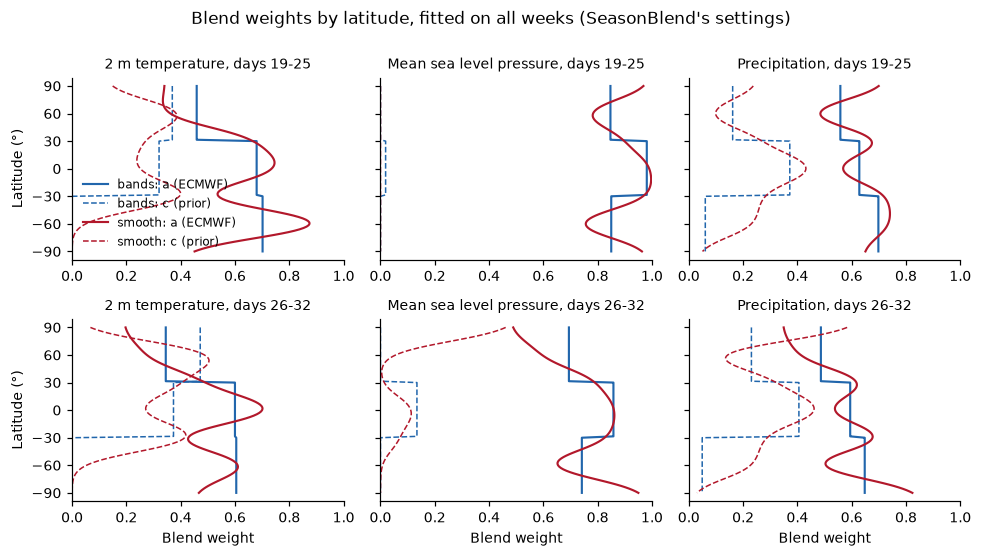

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(9, 5), sharey=True)
for j, (v, w) in enumerate(PAIRS):
    ax = axs[w - 1, VARIABLES.index(v)]
    z = rows[(v, w)]
    for key, col in (("A", "#2166ac"), ("B", "#b2182b")):
        _, _, a, c, _ = r1.in_sample(z["terms"], schemes[key], ctrl_combo(z))
        ax.plot(a, LAT, color=col, lw=1.4, label=f"{'bands' if key == 'A' else 'smooth'}: a (ECMWF)")
        ax.plot(c, LAT, color=col, lw=1.0, ls="--", label=f"{'bands' if key == 'A' else 'smooth'}: c (prior)")
    ax.set_title(f"{NAMES[v]}, {WIN[w]}"); ax.set_xlim(0, 1); ax.set_yticks(range(-90, 91, 30))
    if VARIABLES.index(v) == 0: ax.set_ylabel("Latitude (°)")
    if w == 2: ax.set_xlabel("Blend weight")
axs[0, 0].legend(loc="lower left", frameon=False)
fig.suptitle("Blend weights by latitude, fitted on all weeks (SeasonBlend's settings)", y=1.0)
fig.tight_layout(); savefig(fig, "fig2_weight_profiles")

## 5. Regional evaluation, including Africa

Region scores need grid-point forecasts. The per-week fields were stored for SeasonBlend's
selected setting, so here the setting is held at that choice for every model, while the blend
weights are still cross-validated per week. Section 4 shows how often the folds pick that
setting. Regions are fixed boxes, chosen before scoring:

- tropics: 30°S to 30°N;
- northern and southern extratropics;
- Africa: 35°S to 37.5°N, 18°W to 52°E;
- equatorial East Africa: 5°S to 5°N, 33°E to 42°E. This covers Kenya, Uganda and northern
  Tanzania, the core of the bimodal short- and long-rains regime;
- southern Africa: 35°S to 15°S, 12°E to 40°E.

Land-only rules follow the leaderboard: tas and pr over land, with arid points skipped for pr.

In [10]:
lon180 = np.where(LON > 180, LON - 360, LON)
LA, LO = np.meshgrid(LAT, lon180, indexing="ij")
REG = {"Global": np.ones_like(LA, bool), "Tropics 30S-30N": np.abs(LA) <= 30, "N extratropics": LA > 30,
       "S extratropics": LA < -30, "Africa": (LA >= -35) & (LA <= 37.5) & (LO >= -18) & (LO <= 52),
       "Equatorial East Africa": (LA >= -5) & (LA <= 5) & (LO >= 33) & (LO <= 42),
       "Southern Africa": (LA >= -35) & (LA <= -15) & (LO >= 12) & (LO <= 40)}

def rps_field(p, oh):
    # p, oh (5, ny, nx) -> RPS per point; NaN where the leaderboard skips the point
    d = np.cumsum(p, 0)[:4] - np.cumsum(np.nan_to_num(oh), 0)[:4]
    r = (d * d).sum(0); r[~np.isfinite(oh[0])] = np.nan
    return r

qm = {p: np.load(RD / f"qm_{p[0]}_p{p[1]}.npz") for p in PAIRS if (RD / f"qm_{p[0]}_p{p[1]}.npz").exists()}
fields = {}   # (model, var, w) -> (N, ny, nx) RPS per point and week
outer = {}    # (model, var, w) -> (N, 2, ny, nx) cross-validated probabilities of the outer quintiles (for section 6)
for v, w in PAIRS:
    z = rows[(v, w)]; k = ctrl_combo(z); N = len(z["inits"])
    W = z["score_weight"]
    fixedA = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), schemes["A"], combos=[k])
    fixedB = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), schemes["B"], combos=[k])
    pe, pp, oh = z["p_ens"].astype(float), z["p_prior"].astype(float), z["onehot"].astype(float)
    for name, res in (("SeasonBlend", fixedA), ("R1-B", fixedB)):
        F = np.empty((N,) + LA.shape)
        O = np.empty((N, 2) + LA.shape, np.float32)
        for i in range(N):
            a = res.a_rows[i][None, :, None]; c = res.c_rows[i][None, :, None]
            prob = calib.finalize(a * pe[i] + c * pp[i] + (1 - a - c) * 0.2)
            F[i] = rps_field(prob, oh[i]); O[i] = prob[[0, 4]]
        fields[(name, v, w)] = F; outer[(name, v, w)] = O
    fields[("Climatology", v, w)] = np.stack([rps_field(np.full((5,) + LA.shape, 0.2), oh[i]) for i in range(N)])
    if (v, w) in qm:
        q = qm[(v, w)]
        assert list(q["inits"]) == list(z["inits"])
        fields[("Quantile mapping", v, w)] = np.stack([rps_field(q["p_qm"][i].astype(float), oh[i]) for i in range(N)])
        fields[("Raw ECMWF", v, w)] = np.stack([rps_field(q["p_raw"][i].astype(float), oh[i]) for i in range(N)])
    fields[("W", v, w)] = W
print("models:", sorted({k[0] for k in fields if k[0] != "W"}))

models: ['Climatology', 'Quantile mapping', 'R1-B', 'Raw ECMWF', 'SeasonBlend']


In [11]:
def region_scores(model, v, w, mask):
    F, Fc, W = fields[(model, v, w)], fields[("Climatology", v, w)], fields[("W", v, w)] * mask
    num = np.array([np.nansum(F[i] * W) for i in range(F.shape[0])])
    den = np.array([np.nansum(Fc[i] * W) for i in range(F.shape[0])])
    return num, den

models = [m for m in ("Raw ECMWF", "Quantile mapping", "SeasonBlend", "R1-B") if all((m, v, w) in fields for v, w in PAIRS)]
reg = []
for rname, mask in REG.items():
    for v, w in PAIRS:
        rowd = {"region": rname, "variable": v, "window": w}
        base = None
        for m in models:
            num, den = region_scores(m, v, w, mask)
            rowd[m] = 1 - num.sum() / den.sum()
        reg.append(rowd)
reg = pd.DataFrame(reg)
reg.to_csv(OUT / "R1_region_scores.csv", index=False)
summary = reg.groupby("region", sort=False)[models].mean()
print("Cross-validated RPSS by region (ratio convention within region; mean over the 6 variable/window pairs;\n"
      "tas and pr over land only, so ocean-dominated regions are scored mostly on mslp)")
summary.round(3)

Cross-validated RPSS by region (ratio convention within region; mean over the 6 variable/window pairs;
tas and pr over land only, so ocean-dominated regions are scored mostly on mslp)


,Raw ECMWF,Quantile mapping,SeasonBlend,R1-B
region,,,,
Global,-0.028,0.068,0.115,0.114
Tropics 30S-30N,-0.060,0.145,0.188,0.187
N extratropics,-0.016,-0.015,0.045,0.044
S extratropics,0.032,0.020,0.047,0.045
Africa,-0.079,0.096,0.152,0.151
Equatorial East Africa,-0.134,0.088,0.132,0.131
Southern Africa,0.011,0.022,0.078,0.077


In [12]:
afr = []
for rname in ("Africa", "Equatorial East Africa", "Southern Africa", "Global"):
    for m in [x for x in models if x != "SeasonBlend"]:
        A_ = np.full((len(PAIRS), 42), np.nan); B_ = A_.copy(); Cl = A_.copy()
        for j, (v, w) in enumerate(PAIRS):
            na, da = region_scores("SeasonBlend", v, w, REG[rname]); nb, _ = region_scores(m, v, w, REG[rname])
            A_[j, :len(na)], B_[j, :len(nb)], Cl[j, :len(da)] = na, nb, da
        d = r1.block_bootstrap_delta(A_, B_, Cl, block=4, n_boot=4000, convention="ratio")
        afr.append({"region": rname, "model minus SeasonBlend": m, **d})
afr = pd.DataFrame(afr)
afr.to_csv(OUT / "R1_region_bootstrap.csv", index=False)
afr.round(4)

,region,model minus SeasonBlend,est,lo90,hi90,p_better,block
0,Africa,Raw ECMWF,-0.2313,-0.2830,-0.1767,0.0000,4
1,Africa,Quantile mapping,-0.0561,-0.0762,-0.0358,0.0000,4
2,Africa,R1-B,-0.0011,-0.0036,0.0011,0.2435,4
3,Equatorial East Africa,Raw ECMWF,-0.2666,-0.3442,-0.1918,0.0000,4
4,Equatorial East Africa,Quantile mapping,-0.0444,-0.1051,0.0143,0.1078,4
5,Equatorial East Africa,R1-B,-0.0007,-0.0051,0.0033,0.3982,4
6,Southern Africa,Raw ECMWF,-0.0667,-0.0977,-0.0380,0.0000,4
7,Southern Africa,Quantile mapping,-0.0563,-0.0768,-0.0378,0.0000,4
8,Southern Africa,R1-B,-0.0008,-0.0032,0.0018,0.2860,4
9,Global,Raw ECMWF,-0.1437,-0.1548,-0.1337,0.0000,4


## 6. Reliability and sharpness

Five-category reliability for the outer quintiles (the categories that carry most of the
signal). Forecast probabilities are binned, and the observed frequency in each bin is area
weighted. Points and weeks are pooled across both windows, over leaderboard points only.
Bins holding under 0.2% of the weight are not drawn, but they stay in `R1_reliability.csv`.
The table after the figure gives the reliability component, the share-weighted mean of
(forecast - observed)^2 (lower is better).

Reliability component x 1000 (lower is better)


model                      Raw ECMWF  Quantile mapping  SeasonBlend  R1-B
variable category                                                        
mslp     highest quintile       6.73              3.07         0.38  0.41
         lowest quintile       22.59              2.07         0.35  0.34
pr       highest quintile       8.64              8.69         0.32  0.31
         lowest quintile        4.23              5.95         0.19  0.18
tas      highest quintile      25.82             14.02         0.76  0.86
         lowest quintile       60.28             11.38         1.38  1.68
mean                           21.38              7.53         0.57  0.63

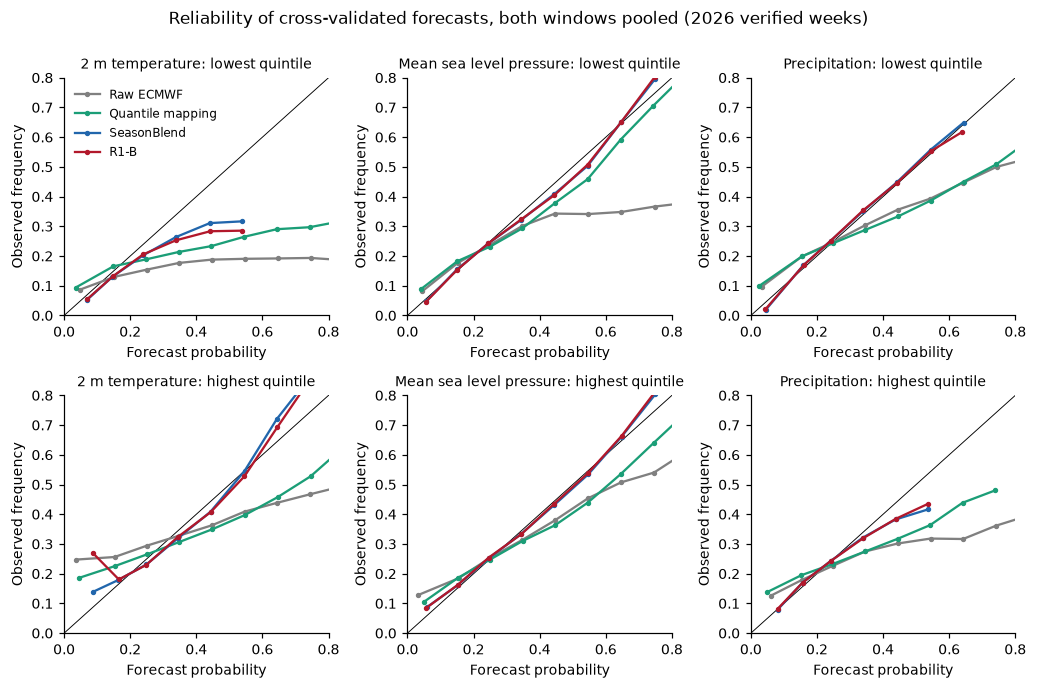

In [13]:
bins = np.linspace(0, 1, 11)
def reliability(model, v, k):
    fp, ob, wt = [], [], []
    for w in WINDOWS:
        z = rows[(v, w)]; oh = z["onehot"]; W = fields[("W", v, w)]
        if model == "SeasonBlend" or model == "R1-B":
            P = outer[(model, v, w)][:, 0 if k == 0 else 1].astype(float)   # cached in section 5
        else:
            P = qm[(v, w)]["p_qm" if model == "Quantile mapping" else "p_raw"][:, k].astype(float)
        ok = np.isfinite(oh[:, k]) & (W[None] > 0)
        fp.append(P[ok]); ob.append(oh[:, k][ok]); wt.append(np.broadcast_to(W, oh[:, k].shape)[ok])
    fp, ob, wt = map(np.concatenate, (fp, ob, wt))
    b = np.clip(np.digitize(fp, bins) - 1, 0, len(bins) - 2)
    f = np.array([np.average(fp[b == j], weights=wt[b == j]) if (b == j).any() else np.nan for j in range(len(bins) - 1)])
    o = np.array([np.average(ob[b == j], weights=wt[b == j]) if (b == j).any() else np.nan for j in range(len(bins) - 1)])
    n = np.array([wt[b == j].sum() for j in range(len(bins) - 1)]) / wt.sum()
    return f, o, n

cols = {"Raw ECMWF": "0.5", "Quantile mapping": "#1b9e77", "SeasonBlend": "#2166ac", "R1-B": "#b2182b"}
fig, axs = plt.subplots(2, 3, figsize=(9.5, 6.2))
rel_rows = []
for jv, v in enumerate(VARIABLES):
    for jk, (k, lab) in enumerate(((0, "lowest quintile"), (4, "highest quintile"))):
        ax = axs[jk, jv]; ax.plot([0, 1], [0, 1], color="k", lw=0.6)
        for m in models:
            f, o, n = reliability(m, v, k)
            show = n >= 0.002   # hide bins holding under 0.2% of the weight (too few forecasts to estimate a frequency)
            ax.plot(np.where(show, f, np.nan), np.where(show, o, np.nan), "-o", ms=2.5, color=cols[m], label=m)
            rel_rows += [{"variable": v, "category": lab, "model": m, "bin": j, "mean_forecast": f[j], "observed": o[j], "share": n[j]} for j in range(len(f))]
        ax.set_xlim(0, 0.8); ax.set_ylim(0, 0.8); ax.set_title(f"{NAMES[v]}: {lab}")
        ax.set_xlabel("Forecast probability"); ax.set_ylabel("Observed frequency")
axs[0, 0].legend(frameon=False, loc="upper left")
fig.suptitle("Reliability of cross-validated forecasts, both windows pooled (2026 verified weeks)", y=1.0)
fig.tight_layout(); savefig(fig, "fig3_reliability")
relt = pd.DataFrame(rel_rows); relt.to_csv(OUT / "R1_reliability.csv", index=False)
relt = relt.dropna(); relt["rel"] = relt["share"] * (relt["mean_forecast"] - relt["observed"]) ** 2
reltab = relt.groupby(["variable", "category", "model"])["rel"].sum().unstack("model")[models] * 1000
reltab.loc[("mean", ""), :] = reltab.mean()
print("Reliability component x 1000 (lower is better)")
reltab.round(2)

## 7. Where does R1-B change skill? Maps of the RPSS difference

The map shows the per-point difference in cross-validated RPSS, R1-B minus SeasonBlend, for
days 19-25, as $\sum_i(\mathrm{RPS}^{A}_i-\mathrm{RPS}^{B}_i)/\sum_i \mathrm{RPS}^{clim}_i$.
Positive (red) means R1-B is better. Grey points are not scored on the leaderboard.

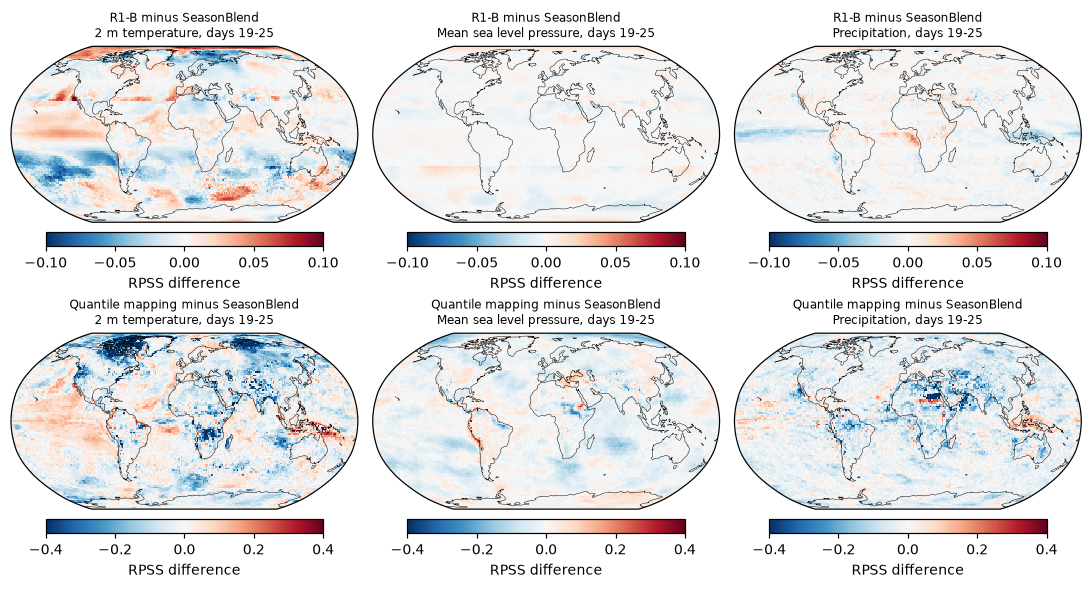

In [14]:
try:
    import cartopy.crs as ccrs
    proj = ccrs.Robinson(); kw = {"transform": ccrs.PlateCarree()}
except Exception:
    ccrs = None; proj = None; kw = {}
lon_p = np.r_[lon180[lon180 < 0], lon180[lon180 >= 0]]; order = np.r_[np.where(lon180 < 0)[0], np.where(lon180 >= 0)[0]]
pairs_map = [("tas", 1), ("mslp", 1), ("pr", 1)]
comps = [("R1-B", "SeasonBlend")] + ([("Quantile mapping", "SeasonBlend")] if "Quantile mapping" in models else [])
fig = plt.figure(figsize=(10, 2.7 * len(comps)))
for r_, (mb, ma) in enumerate(comps):
    for c_, (v, w) in enumerate(pairs_map):
        ax = fig.add_subplot(len(comps), 3, r_ * 3 + c_ + 1, projection=proj) if proj else fig.add_subplot(len(comps), 3, r_ * 3 + c_ + 1)
        D = (np.nansum(fields[(ma, v, w)], 0) - np.nansum(fields[(mb, v, w)], 0)) / np.nansum(fields[("Climatology", v, w)], 0)
        D[~np.isfinite(fields[("Climatology", v, w)]).any(0)] = np.nan
        lim = 0.1 if mb == "R1-B" else 0.4
        im = ax.pcolormesh(lon_p, LAT, D[:, order], cmap="RdBu_r", vmin=-lim, vmax=lim, shading="nearest", **kw)
        if proj:
            ax.coastlines(lw=0.3); ax.set_global()
        ax.set_title(f"{mb} minus {ma}\n{NAMES[v]}, {WIN[w]}", fontsize=8)
        fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.8, pad=0.04, label="RPSS difference")
fig.tight_layout(); savefig(fig, "fig4_skill_difference_maps")

## 8. Climate-regime conditioning: what the data can and cannot support

**R1-C (ENSO).** Section 3 shows how Niño 3.4 evolved over the 42 verified runs: it rose almost
steadily from La Niña in January to a very strong El Niño. ENSO state is therefore close to
collinear with time and season in this sample. An ENSO-dependent blend weight fitted on these
runs could not be told apart from a seasonal or trend effect. This analysis does **not** fit
one, and records the limitation in the decision table. Testing it needs multi-year
reforecasts (section 10).

**R1-D (MJO, exploratory).** MJO amplitude varies from week to week, so a two-class split
(active/inactive at initialisation, threshold 1 as in Wheeler and Hendon 2004) is
identifiable in principle. Each class gets its own band weights inside each fold. With only a
handful of inactive weeks in a fold, the class falls back to pooled weights. Phase-dependent
weights (8 phases) are not attempted.

In [15]:
mjo = []
for v, w in PAIRS:
    z = rows[(v, w)]
    st = pd.DataFrame({"init": pd.to_datetime(z["inits"])}).merge(idx, on="init", how="left")
    cls = st["mjo_active"].fillna(1).astype(int).to_numpy()
    res = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), schemes["A"], classes=cls, min_class=6)
    cv[("D", v, w)] = res
    d = r1.block_bootstrap_delta(cv[("A", v, w)].rps, res.rps, res.clim, block=4, n_boot=4000)
    mjo.append({"variable": v, "window": w, "inactive weeks": int((cls == 0).sum()), "active weeks": int((cls == 1).sum()),
                "SeasonBlend": cv[("A", v, w)].rpss_leaderboard, "MJO two-class": res.rpss_leaderboard, **{f"delta_{k}": d[k] for k in ("est", "lo90", "hi90", "p_better")}})
mjo = pd.DataFrame(mjo)
RD_, _, _ = stack_by_date("D")
dm = r1.block_bootstrap_delta(RA, RD_, CL, block=4, n_boot=4000)
print(f"Variable-averaged difference (MJO two-class minus SeasonBlend): {dm['est']:+.4f} [{dm['lo90']:+.4f}, {dm['hi90']:+.4f}], P(better) {dm['p_better']:.2f}")
mjo.to_csv(OUT / "R1D_mjo_two_class.csv", index=False)
mjo.round(4)

Variable-averaged difference (MJO two-class minus SeasonBlend): -0.0011 [-0.0027, +0.0002], P(better) 0.10


,variable,window,inactive weeks,active weeks,SeasonBlend,MJO two-class,delta_est,delta_lo90,delta_hi90,delta_p_better
0,tas,1,13,29,0.1079,0.1068,-0.0012,-0.0021,-0.0003,0.0165
1,tas,2,13,28,0.0881,0.0866,-0.0015,-0.0024,-0.0007,0.0002
2,mslp,1,13,29,0.1809,0.1787,-0.0022,-0.0038,-0.0009,0.0008
3,mslp,2,13,28,0.1403,0.1393,-0.0010,-0.0082,0.0054,0.4295
4,pr,1,13,29,0.0815,0.0811,-0.0004,-0.0009,0.0002,0.1268
5,pr,2,13,28,0.0707,0.0703,-0.0004,-0.0007,-0.0000,0.0492


### 8b. Post-hoc diagnostic: why raw counts beat SeasonBlend in the southern extratropics

**Status: exploratory.** This test was added *after* the regional table in section 5 had been
seen, so it is a hypothesis check, not a confirmatory result.

Section 5 shows the raw ensemble ahead of SeasonBlend south of 30°S for mslp and pr, and
for southern-Africa rainfall. Two explanations are possible:

1. **Wrong settings.** The one setting combination (bias correction, spread, smoothing)
   chosen per variable for the whole globe is wrong for high southern latitudes.
2. **Estimation noise.** Where the ensemble is already close to calibrated, the gain from
   fitting weights is smaller than the noise in weights estimated from about 38 weeks.

Two checks separate them:

- **Hypothesis 1:** every band chooses its own combination inside each fold
  (`r1.cv_scores_band_settings`), with 3 bands and with 6 bands of 30°.
- **Hypothesis 2:** compare in-sample and cross-validated scores for the 30–90°S band.

In [16]:
B6 = r1.band_basis(((90, 60), (60, 30), (30, 0), (0, -30), (-30, -60), (-60, -90)))
bs = []
for name, Bx in (("3 bands, own settings", r1.band_basis()), ("6 bands, own settings", B6)):
    for v, w in PAIRS:
        z = rows[(v, w)]
        cv[(name, v, w)] = r1.cv_scores_band_settings(z["terms"], z["mon_ord"], int(z["exclude_days"]), Bx)
    RX, _, _ = stack_by_date(name)
    for b in (1, 2, 4, 8):
        bs.append({"variant": name, **r1.block_bootstrap_delta(RA, RX, CL, block=b, n_boot=4000)})
bs = pd.DataFrame(bs)
bs.to_csv(OUT / "R1E_band_settings_bootstrap.csv", index=False)
print("Difference from SeasonBlend (leaderboard convention, variable-averaged):")
display(bs.round(4))

# hypothesis 2: in-sample versus cross-validated skill of the 30-90S band, control settings
sh = LAT < -30
diag = []
for v, w in PAIRS:
    z = rows[(v, w)]; k = ctrl_combo(z)
    flat = z["terms"].reshape(-1, *z["terms"].shape[3:])
    tot = flat[k][:, sh].sum(axis=(0, 1)); clim_sh = tot[5]
    a, c = calib.solve_blend(tot)
    ins = 1 - (a*a*tot[0] + 2*a*c*tot[1] + c*c*tot[2] - 2*a*tot[3] - 2*c*tot[4] + tot[5]) / clim_sh
    res = r1.cv_scores(z["terms"], z["mon_ord"], int(z["exclude_days"]), schemes["A"], combos=[k])
    cvs = 1 - sum(r1.rps_rows(flat[k, i][sh], res.a_rows[i][sh], res.c_rows[i][sh]) for i in range(len(res.rps))) / clim_sh
    raw = qm[(v, w)]["p_raw"] if (v, w) in qm else None
    rawsc = np.nan
    if raw is not None:
        num = sum(np.nansum((rps_field(raw[i].astype(float), z["onehot"][i].astype(float)) * z["score_weight"])[sh]) for i in range(len(res.rps)))
        rawsc = 1 - num / clim_sh
    diag.append({"variable": v, "window": w, "in-sample (fitted on all weeks)": ins, "cross-validated": cvs,
                 "raw counts (nothing fitted)": rawsc, "ensemble weight a, min over folds": res.a_rows[:, sh].min(),
                 "a, max over folds": res.a_rows[:, sh].max()})
diag = pd.DataFrame(diag)
diag.to_csv(OUT / "R1E_southern_band_diagnostic.csv", index=False)
diag.round(4)

Difference from SeasonBlend (leaderboard convention, variable-averaged):


,variant,est,lo90,hi90,p_better,block
0,"3 bands, own settings",0.0001,-0.0006,0.0008,0.6080,1
1,"3 bands, own settings",0.0001,-0.0007,0.0009,0.6072,2
2,"3 bands, own settings",0.0001,-0.0006,0.0009,0.6058,4
3,"3 bands, own settings",0.0001,-0.0005,0.0008,0.6060,8
4,"6 bands, own settings",-0.0021,-0.0030,-0.0012,0.0000,1
5,"6 bands, own settings",-0.0021,-0.0031,-0.0011,0.0000,2
6,"6 bands, own settings",-0.0021,-0.0032,-0.0011,0.0000,4
7,"6 bands, own settings",-0.0021,-0.0033,-0.0011,0.0000,8


,variable,window,in-sample (fitted on all weeks),cross-validated,raw counts (nothing fitted),"ensemble weight a, min over folds","a, max over folds"
0,tas,1,0.0633,0.0564,-0.0025,0.6126,0.8286
1,tas,2,0.0413,0.0346,-0.0214,0.4954,0.7023
2,mslp,1,0.0906,0.0840,0.0901,0.7414,0.9370
3,mslp,2,0.0589,0.0482,0.0521,0.5967,0.8374
4,pr,1,0.0392,0.0321,0.0412,0.5710,0.7692
5,pr,2,0.0311,0.0241,0.0322,0.5400,0.7208


## 9. The mentor's recommendation: empirical quantile mapping (xsdba)

`aiwq/research_qm.py` trains `xsdba.EmpiricalQuantileMapping` (15 quantiles) leave-one-out
on the same weeks, then counts the mapped members in the official quintiles. Anomalies are
taken from the ERA5 20-year median of each target week, so the seasonal cycle does not dominate
the mapping. The run is repeated with 20 and 10 training weeks to measure how much the method
depends on sample size.

In [17]:
qrows = []
for v, w in PAIRS:
    if (v, w) not in qm: continue
    q = qm[(v, w)]; cl = q["rps_clim"]
    qrows.append({"variable": v, "window": w, "N": len(cl),
                  "raw ECMWF": np.mean(1 - q["rps_raw"] / cl),
                  "QM, all weeks": np.mean(1 - q["rps_qm"] / cl), "QM, 20 weeks": np.mean(1 - q["rps_qm_n20"] / cl),
                  "QM, 10 weeks": np.mean(1 - q["rps_qm_n10"] / cl), "SeasonBlend": cv[("A", v, w)].rpss_leaderboard})
qtab = pd.DataFrame(qrows)
if len(qtab):
    qtab.loc[len(qtab)] = {"variable": "mean", **qtab.drop(columns=["variable", "window"]).mean().to_dict()}
    # paired difference QM - SeasonBlend (leaderboard convention)
    QA = np.full((len(PAIRS), len(dates)), np.nan); QB = QA.copy(); QC = QA.copy()
    for j, p in enumerate(PAIRS):
        pos = [dates.index(d) for d in rows[p]["inits"]]
        QA[j, pos] = cv[("A",) + p].rps; QB[j, pos] = qm[p]["rps_qm"]; QC[j, pos] = qm[p]["rps_clim"]
    dq = r1.block_bootstrap_delta(QA, QB, QC, block=4, n_boot=4000)
    print(f"QM minus SeasonBlend (variable-averaged, leaderboard convention): {dq['est']:+.4f} [{dq['lo90']:+.4f}, {dq['hi90']:+.4f}]")
    print("check: climatology RPS from both pipelines agree:",
          all(np.allclose(qm[p]["rps_clim"], cv[("A",) + p].clim, rtol=1e-6) for p in PAIRS))
qtab.to_csv(OUT / "R1_quantile_mapping.csv", index=False)
qtab.round(4)

C:\Users\Stephen Nyaranga\AppData\Local\Temp\ipykernel_46648\2853124439.py:11: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  qtab.loc[len(qtab)] = {"variable": "mean", **qtab.drop(columns=["variable", "window"]).mean().to_dict()}


QM minus SeasonBlend (variable-averaged, leaderboard convention): -0.0472 [-0.0589, -0.0347]
check: climatology RPS from both pipelines agree: True


,variable,window,N,raw ECMWF,"QM, all weeks","QM, 20 weeks","QM, 10 weeks",SeasonBlend
0,tas,1.0,42.0,-0.1655,0.0381,0.0138,-0.0321,0.1079
1,tas,2.0,41.0,-0.1927,0.0046,-0.0186,-0.0606,0.0881
2,mslp,1.0,42.0,0.0767,0.1699,0.1461,0.0963,0.1809
3,mslp,2.0,41.0,0.0449,0.1261,0.0938,0.0544,0.1403
4,pr,1.0,42.0,0.0307,0.0311,0.0093,-0.0402,0.0815
5,pr,2.0,41.0,0.0171,0.0161,-0.0084,-0.0534,0.0707
6,mean,NaN,41.5,-0.0315,0.0643,0.0393,-0.0059,0.1116


## 10. Decision record (Phase 11 checklist)

In [18]:
mb = boot[(boot["scheme"].str.startswith("R1-B")) & (boot["convention"] == "leaderboard")].set_index("block")
dec = {
    "R1-A control reproduces SeasonBlend": bool((audit["max |weekly RPS diff|"] < 1e-9).all() and (audit["max |weight diff|"] < 1e-12).all()),
    "R1-B mean difference (lb, 4-week blocks)": [round(mb.loc[4, "est"], 4), round(mb.loc[4, "lo90"], 4), round(mb.loc[4, "hi90"], 4)],
    "R1-B interval above zero for all block lengths": bool((mb["lo90"] > 0).all()),
    "R1-B forward-split mean difference": round(float(fwd.iloc[-1]["difference"]), 4),
    "R1-D MJO two-class mean difference": [round(dm["est"], 4), round(dm["lo90"], 4), round(dm["hi90"], 4)],
    "R1-C ENSO conditioning identifiable from 2026 runs": False,
    **{f"R1-E post-hoc: {r['variant']} mean difference (4-week blocks)": [round(r["est"], 4), round(r["lo90"], 4), round(r["hi90"], 4)]
       for _, r in bs[bs["block"] == 4].iterrows()},
    "Promote any variant to a registered model": False,
}
if len(qtab):
    dec["QM mean difference vs SeasonBlend"] = [round(dq["est"], 4), round(dq["lo90"], 4), round(dq["hi90"], 4)]
(OUT / "R1_decision.json").write_text(json.dumps(dec, indent=1))
folds = []
for v, w in PAIRS:
    z = rows[(v, w)]
    for i, d in enumerate(z["inits"]):
        keep = np.abs(z["mon_ord"] - z["mon_ord"][i]) >= int(z["exclude_days"])
        folds.append({"variable": v, "window": w, "init": d, "target_monday": z["mondays"][i], "n_train": int(keep.sum()),
                      "excluded_inits": ";".join(z["inits"][~keep]), "combo_SeasonBlend": int(cv[("A", v, w)].combo[i]),
                      "combo_R1B": int(cv[("B", v, w)].combo[i])})
pd.DataFrame(folds).to_csv(OUT / "R1_folds.csv", index=False)
dec

{'R1-A control reproduces SeasonBlend': True,
 'R1-B mean difference (lb, 4-week blocks)': [np.float64(-0.0009),
  np.float64(-0.0016),
  np.float64(-0.0003)],
 'R1-B interval above zero for all block lengths': False,
 'R1-B forward-split mean difference': -0.0003,
 'R1-D MJO two-class mean difference': [-0.0011, -0.0027, 0.0002],
 'R1-C ENSO conditioning identifiable from 2026 runs': False,
 'R1-E post-hoc: 3 bands, own settings mean difference (4-week blocks)': [0.0001,
  -0.0006,
  0.0009],
 'R1-E post-hoc: 6 bands, own settings mean difference (4-week blocks)': [-0.0021,
  -0.0032,
  -0.0011],
 'Promote any variant to a registered model': False,
 'QM mean difference vs SeasonBlend': [-0.0472, -0.0589, -0.0347]}

## 11. Conclusions

Numbers are cross-validated and use the leaderboard convention (mean of weekly RPSS) unless
stated otherwise. Intervals are 90% paired moving-block bootstrap intervals over weeks, with
4-week blocks, and are insensitive to block lengths 1 to 8.

**What holds up**

- **SeasonBlend is sound.**
  - Reproduced exactly (R1-A).
  - Cross-validated RPSS +0.112, against +0.064 for the empirical quantile mapping and
    -0.032 for the raw ensemble.
  - Best reliability of all candidates: reliability component 0.57 × 10⁻³, against
    7.5 × 10⁻³ for quantile mapping and 21.4 × 10⁻³ for the raw ensemble.
- **Africa.**
  - SeasonBlend's ratio RPSS over Africa is +0.152, ahead of quantile mapping (+0.096) and
    raw (-0.079).
  - Equatorial East Africa: +0.132. Southern Africa: +0.078.

**Negative results (reported, not hidden)**

| Variant | Difference from SeasonBlend [90% interval] | Verdict |
|---|---|---|
| R1-B continuous latitude weights (7 nodes) | -0.0009 [-0.0016, -0.0003] | worse at every block length; forward split -0.0003 |
| 6 bands; 13-node smooth weights | -0.0009; -0.0012 | worse |
| R1-D MJO two-class weights | -0.0011 [-0.0027, +0.0002] | no gain |
| R1-E (post-hoc) own settings per band, 3 bands / 6 bands | +0.0001 [-0.0006, +0.0009] / -0.0021 [-0.0032, -0.0011] | no gain / worse |
| Empirical quantile mapping (xsdba, 15 quantiles) | -0.047 [-0.059, -0.035] | much worse. Falls to -0.006 with 10 training weeks, so it needs far more training data |
| R1-C ENSO-conditioned weights | not estimated | **not identifiable**: Niño 3.4 rose almost monotonically through 2026 and is collinear with season and time |

**Diagnosis**

With one year of runs, the limit on skill is not the *form* of the calibration but the
*estimation noise* of its parameters:

- Every extra degree of freedom (smooth weights, more bands, MJO classes, per-band settings)
  loses skill out of sample.
- South of 30°S the fitted blend beats the raw ensemble in-sample, but loses to it under
  cross-validation for mslp and pr. Example, mslp days 19-25: 0.084 cross-validated, against
  0.090 for raw counts with nothing fitted.
- There, the ensemble weight varies between 0.74 and 0.94 across folds (section 8b).
- Reliability shows one systematic error: the **cold (lowest) temperature quintile is
  over-forecast**, a signature of the warm, El Niño 2026 that the season-only prior and bias
  correction do not anticipate.

**Decision.** No R1 variant is promoted, and SeasonBlend stays unchanged. The next
experiment must add information (more years), not parameters. It is an ocean-state
(ENSO/IOD) conditioned climatological prior, estimated from multi-decade ERA5 and validated
leaving one year out (see `results/experiments/R1/README.md`).